# 3b_gunoncesi — Gün Öncesi Tahmin: Hibrit Model ve Gerçek Hava Tahmini

Amaç: Gün öncesi tahminde resmî Yük Tahmin Planı'nı (test hatası %2,60) geçmek, ya da geçemiyorsak bunu dürüstçe belgelemek.

- **A.** Kurulum, veri ve `3_model` ile aynı ayrım
- **B.** Resmî planın doğrulama dönemindeki hatası
- **C.** Hibrit model: resmî plan ve geçmiş hataları özellik olarak
- **D.** Çok şehirli saatlik hava verisi (Open-Meteo): eğitimde ERA5, doğrulama ve testte gerçek gün öncesi tahmin
- **E.** Model karşılaştırması: doğrulama ve test
- **F.** Hata analizi, en iyi modelin seçimi ve kaydı

**Model seçimi kuralı:** En iyi model **doğrulama** dönemine göre seçiliyor. Test dönemi yalnızca son raporlama için kullanılıyor; seçimde kullanılsaydı test sonucu iyimser olurdu.

**Girdiler:** `data/tr_ozellikli_saatlik.csv`, `data/tr_yuk_plani_saatlik.csv`, `metrics/tr_model_sonuclari.json` (`3_model` çıktısı, eğitim dönemi HDD/CDD bazları)

## A. Kurulum ve Veri

In [8]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import xgboost as xgb

KOK = r"C:\Deep_Learning_to_AI_Agents\Bitirme_Proje_Bonus"
np.random.seed(42)

df = pd.read_csv(os.path.join(KOK, "data", "tr_ozellikli_saatlik.csv"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
lp = pd.read_csv(os.path.join(KOK, "data", "tr_yuk_plani_saatlik.csv"))
lp["date"] = pd.to_datetime(lp["date"])
df = df.merge(lp[["date", "lep"]], on="date", how="left")

with open(os.path.join(KOK, "metrics", "tr_model_sonuclari.json"), encoding="utf-8") as f:
    m3 = json.load(f)
BH_TR, BC_TR = m3["hdd_tabani_egitim_c"], m3["cdd_tabani_egitim_c"]

EGITIM_BIT = pd.Timestamp("2024-10-01T00:00:00+03:00")
DOGRULAMA_BIT = pd.Timestamp("2025-10-01T00:00:00+03:00")
TEST_BIT = pd.Timestamp("2026-09-23T00:00:00+03:00")
df["bolum"] = np.select([df["date"] < EGITIM_BIT, df["date"] < DOGRULAMA_BIT, df["date"] < TEST_BIT],
                        ["egitim", "dogrulama", "test"], default="disarida")

# 3_model ile ayni gun oncesi ozellikleri (dunun sicakligi)
df["lag_48"] = df["consumption"].shift(48)
df["lag_72"] = df["consumption"].shift(72)
df["rol_24_48"] = df["consumption"].shift(48).rolling(24).mean()
df["rol_168_48"] = df["consumption"].shift(48).rolling(168).mean()
df["tavg_dun"] = df["tavg_c"].shift(24)
df["hdd_dun"] = np.maximum(0, BH_TR - df["tavg_dun"])
df["cdd_dun"] = np.maximum(0, df["tavg_dun"] - BC_TR)

TAKVIM = ["saat", "gun", "ay", "hafta_sonu", "tatil_saat", "idari_izin", "bayram_gun_no",
          "bayram_once_gun", "bayram_sonra_gun"]
GO_LAG = ["lag_48", "lag_72", "lag_168", "rol_24_48", "rol_168_48"]
F_GO_DUN = TAKVIM + ["tavg_dun", "hdd_dun", "cdd_dun"] + GO_LAG

def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"RMSPE": float(np.sqrt(np.mean(((y - p) / y) ** 2))),
            "MAPE_%": float(np.mean(np.abs((y - p) / y)) * 100),
            "MAE_MWh": float(np.mean(np.abs(y - p)))}

print(df.groupby("bolum")["date"].agg(["min", "max", "count"]).to_string())
print(f"Egitim donemi bazlari (3_model): HDD {BH_TR} C, CDD {BC_TR} C")

                                min                       max  count
bolum                                                               
disarida  2026-09-23 00:00:00+03:00 2026-09-27 23:00:00+03:00    120
dogrulama 2024-10-01 00:00:00+03:00 2025-09-30 23:00:00+03:00   8760
egitim    2016-04-01 00:00:00+03:00 2024-09-30 23:00:00+03:00  74520
test      2025-10-01 00:00:00+03:00 2026-09-22 23:00:00+03:00   8568
Egitim donemi bazlari (3_model): HDD 14.0 C, CDD 17.0 C


# A2: Resmi planin veri kalitesi

In [9]:
# A2: Resmi planin veri kalitesi
oran = df["consumption"] / df["lep"]
sorun = df["lep"].notna() & ((df["lep"] <= 0) | (oran > 2) | (oran < 0.5))
print("Supheli resmi plan saati:", int(sorun.sum()))
if sorun.any():
    print("Bolumlere gore:", df.loc[sorun, "bolum"].value_counts().to_dict())
    print(df.loc[sorun, ["date", "consumption", "lep", "bolum"]].head(20).to_string(index=False))
df.loc[sorun, "lep"] = np.nan
print("Temizlik sonrasi resmi planin eksik oldugu saat:", int(df["lep"].isna().sum()))

Supheli resmi plan saati: 72
Bolumlere gore: {'egitim': 72}
                     date  consumption  lep  bolum
2016-04-02 00:00:00+03:00     28487.31  0.0 egitim
2016-04-02 01:00:00+03:00     27017.06  0.0 egitim
2016-04-02 02:00:00+03:00     25924.33  0.0 egitim
2016-04-02 03:00:00+03:00     25080.56  0.0 egitim
2016-04-02 04:00:00+03:00     24928.11  0.0 egitim
2016-04-02 05:00:00+03:00     25285.42  0.0 egitim
2016-04-02 06:00:00+03:00     24922.81  0.0 egitim
2016-04-02 07:00:00+03:00     25584.85  0.0 egitim
2016-04-02 08:00:00+03:00     29146.65  0.0 egitim
2016-04-02 09:00:00+03:00     31464.98  0.0 egitim
2016-04-02 10:00:00+03:00     32353.63  0.0 egitim
2016-04-02 11:00:00+03:00     32837.06  0.0 egitim
2016-04-02 12:00:00+03:00     31278.15  0.0 egitim
2016-04-02 13:00:00+03:00     31151.64  0.0 egitim
2016-04-02 14:00:00+03:00     30865.46  0.0 egitim
2016-04-02 15:00:00+03:00     30512.89  0.0 egitim
2016-04-02 16:00:00+03:00     30017.47  0.0 egitim
2016-04-02 17:00:00+03

## B. Resmî Planın Doğrulama Dönemindeki Hatası

`3_model`'de gün öncesi modelimiz doğrulamada %2,36-2,47, testte %2,85-2,87 hata yaptı. Resmî planın doğrulama dönemindeki hatası bilinmiyordu. Bu hücre, test dönemindeki farkın modelin kendi zayıflığından mı, yoksa test döneminin genel olarak daha zor olmasından mı kaynaklandığını gösterir.

In [10]:
for b in ["egitim", "dogrulama", "test"]:
    d = df[(df["bolum"] == b)].dropna(subset=["lep", "consumption"])
    m = metrik(d["consumption"], d["lep"])
    print(f"Resmi plan | {b:9s}: {len(d):6d} saat | RMSPE {m['RMSPE']:.4f} | MAPE %{m['MAPE_%']:.2f}")

Resmi plan | egitim   :  74448 saat | RMSPE 0.0414 | MAPE %2.80
Resmi plan | dogrulama:   8760 saat | RMSPE 0.0503 | MAPE %3.23
Resmi plan | test     :   8544 saat | RMSPE 0.0359 | MAPE %2.60


## C. Hibrit Model Özellikleri

Resmî Yük Tahmin Planı, bir sonraki gün için bir önceki gün yayımlanıyor. Yani gün öncesi tahmin anında bilinen bir bilgi, özellik olarak kullanılabilir.

**Eklenen özellikler:**
- `lep`: Hedef saat için resmî plan.
- `lep_hata_48`, `lep_hata_168`: Planın 48 ve 168 saat önceki hatası (plan − gerçek). Tahmin anında bilinen en yakın hatalar.
- `lep_hata_ort_7g`: 48 saat önce biten bir haftalık ortalama plan hatası. Planın yakın dönemdeki sistematik sapmasını yakalamak için.

**İki hedef tanımı:**
- **Seviye:** Doğrudan tüketimi tahmin eder.
- **Oran:** Planın düzeltme oranını tahmin eder: (tüketim / plan − 1). Tahmin = plan × (1 + oran). Karar ağaçları eğitimde görmedikleri seviyelere uzanamadığı için, yıllar içinde büyüyen bir seride ölçekten bağımsız bir hedef daha güvenli olabilir. Hangisinin daha iyi olduğunu doğrulama sonucu belirleyecek.

In [11]:
df["lep_hata"] = df["lep"] - df["consumption"]
df["lep_hata_48"] = df["lep_hata"].shift(48)
df["lep_hata_168"] = df["lep_hata"].shift(168)
df["lep_hata_ort_7g"] = df["lep_hata"].shift(48).rolling(168, min_periods=120).mean()
df["lep_oran_hedef"] = df["consumption"] / df["lep"] - 1
HIBRIT = ["lep", "lep_hata_48", "lep_hata_168", "lep_hata_ort_7g"]
print(df[["lep", "lep_hata_48", "lep_hata_168", "lep_hata_ort_7g", "lep_oran_hedef"]].describe().round(3).to_string())

             lep  lep_hata_48  lep_hata_168  lep_hata_ort_7g  lep_oran_hedef
count  91872.000    91824.000     91704.000        91777.000       91872.000
mean   35782.514     -217.416      -216.986         -216.927           0.007
std     6352.019     1453.817      1454.516          773.354           0.041
min    17237.000   -13036.080    -13036.080        -3433.603          -0.485
25%    31100.000     -901.418      -901.025         -614.185          -0.013
50%    35400.000     -182.790      -182.100         -150.912           0.005
75%    40100.000      468.645       469.633          244.089           0.025
max    60026.000    27027.630     27027.630         2948.913           0.541


## D. Çok Şehirli Saatlik Hava Verisi (Open-Meteo)

**Neden:** `3_model`'de Ankara'nın günlük ortalama sıcaklığı gün öncesi modele ek bilgi katmadı. Hedef günün gerçek sıcaklığını kullanan model, dünün sıcaklığını kullanandan daha iyi değildi.

**Kaynaklar (API anahtarı gerektirmiyor):**
- **Eğitim:** Historical Weather API (`archive-api.open-meteo.com/v1/archive`), ERA5 tabanlı saatlik gerçekleşen sıcaklık.
- **Doğrulama ve test:** Previous Runs API (`previous-runs-api.open-meteo.com/v1/forecast`), `temperature_2m_previous_day1` değişkeni. Her saat için, **24 saat önce yapılmış** tahmini veriyor. Model olarak GFS (`gfs_seamless`) seçildi, çünkü 2 metre sıcaklık arşivi Mart 2021'e kadar gidiyor ve doğrulama dönemini tamamen kapsıyor. Resmî plan bir önceki gün hazırlandığı için 24 saatlik tahmin ufku gerçekçi bir yaklaşım.

**Şehirler ve ağırlıklar:** Nüfusu en büyük altı il. Ağırlık, TÜİK Adrese Dayalı Nüfus Kayıt Sistemi 2024 sonuçlarındaki il nüfusu. Koordinatlar yaklaşık il merkezleri. Bu altı il toplam nüfusun yaklaşık %40'ını oluşturuyor. İstanbul, İzmir, Antalya ve Adana'nın sıcak kıyı iklimi, Ankara'nın tek başına temsil edemediği soğutma yükünü yakalamak için özellikle önemli.

**Uyarı:** Open-Meteo'nun ücretsiz kullanımı ticari olmayan projeler içindir ve bir kullanım sınırı var. İstekler yıl ve çeyrek parçalarına bölünüyor, istekler arasında bekleniyor, ve sonuçlar önbelleğe alınıyor.

In [12]:
SEHIRLER = {  # il: (enlem, boylam, TUIK 2024 nufusu)
    "istanbul": (41.01, 28.98, 15701602),
    "ankara":   (39.93, 32.86, 5864049),
    "izmir":    (38.42, 27.14, 4493242),
    "bursa":    (40.19, 29.06, 3238618),
    "antalya":  (36.90, 30.70, 2722103),
    "adana":    (37.00, 35.32, 2280484),
}
toplam_nufus = sum(v[2] for v in SEHIRLER.values())
AGIRLIK = {k: v[2] / toplam_nufus for k, v in SEHIRLER.items()}
print("Agirliklar:", {k: round(v, 3) for k, v in AGIRLIK.items()})

def om_get(url, params):
    for deneme, bekle in enumerate([0, 10, 30, 60, 120], start=1):
        time.sleep(bekle)
        try:
            r = requests.get(url, params=params, timeout=120)
            if r.status_code == 200:
                return r.json()
            print(f"  deneme {deneme}: HTTP {r.status_code} {r.text[:150]}")
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            print(f"  deneme {deneme}: {str(e)[:150]}")
    raise RuntimeError(f"Open-Meteo istegi basarisiz: {params.get('start_date')}")

def om_seri(js, degisken):
    zaman = [t + ":00+03:00" for t in js["hourly"]["time"]]
    return pd.Series(js["hourly"][degisken], index=pd.to_datetime(zaman), dtype="float64")

ARSIV = "https://archive-api.open-meteo.com/v1/archive"
ONCEKI = "https://previous-runs-api.open-meteo.com/v1/forecast"

# D1: tek sehir, bir hafta, iki servis (hata varsa hemen gorunsun)
enl, boy, _ = SEHIRLER["ankara"]
t1 = om_get(ARSIV, {"latitude": enl, "longitude": boy, "start_date": "2025-07-20", "end_date": "2025-07-26",
                    "hourly": "temperature_2m", "timezone": "Europe/Istanbul"})
t2 = om_get(ONCEKI, {"latitude": enl, "longitude": boy, "start_date": "2025-07-20", "end_date": "2025-07-26",
                     "hourly": "temperature_2m_previous_day1", "models": "gfs_seamless", "timezone": "Europe/Istanbul"})
test_arsiv = om_seri(t1, "temperature_2m")
test_tahmin = om_seri(t2, "temperature_2m_previous_day1")
print("ERA5 (arsiv):", len(test_arsiv), "saat, bos:", int(test_arsiv.isna().sum()))
print("Gun oncesi tahmin:", len(test_tahmin), "saat, bos:", int(test_tahmin.isna().sum()))
print("Ankara 20-26 Temmuz 2025, tahmin - ERA5 ortalama mutlak fark:",
      round(float((test_tahmin - test_arsiv).abs().mean()), 2), "C")

Agirliklar: {'istanbul': 0.458, 'ankara': 0.171, 'izmir': 0.131, 'bursa': 0.094, 'antalya': 0.079, 'adana': 0.066}
ERA5 (arsiv): 168 saat, bos: 0
Gun oncesi tahmin: 168 saat, bos: 0
Ankara 20-26 Temmuz 2025, tahmin - ERA5 ortalama mutlak fark: 1.02 C


### D2. Tam dönem indirme (önbellekli)

- **ERA5:** Her şehir için yıl yıl, 2016-04-01 → 2026-09-22.
- **Gün öncesi tahmin:** Her şehir için çeyrek çeyrek, 2024-10-01 (doğrulama başlangıcı) → 2026-09-22.

Dosyalar `data/om_era5_<il>.csv` ve `data/om_tahmin_<il>.csv` olarak kaydediliyor; bir sonraki çalıştırmada diskten okunuyor.

In [13]:
def indir_onbellekli(sehir, tur):
    yol = os.path.join(KOK, "data", f"om_{tur}_{sehir}.csv")
    if os.path.exists(yol):
        s = pd.read_csv(yol)
        return pd.Series(s["deger"].values, index=pd.to_datetime(s["date"]))
    enl, boy, _ = SEHIRLER[sehir]
    parcalar = []
    if tur == "era5":
        araliklar = [(f"{y}-01-01" if y > 2016 else "2016-04-01", f"{y}-12-31" if y < 2026 else "2026-09-22")
                     for y in range(2016, 2027)]
        url, deg, ek = ARSIV, "temperature_2m", {}
    else:
        bas = pd.date_range("2024-10-01", "2026-07-01", freq="QS-OCT")
        araliklar = [(b.strftime("%Y-%m-%d"), min(b + pd.offsets.QuarterEnd(0), pd.Timestamp("2026-09-22")).strftime("%Y-%m-%d"))
                     for b in bas]
        url, deg, ek = ONCEKI, "temperature_2m_previous_day1", {"models": "gfs_seamless"}
    for b, s in araliklar:
        js = om_get(url, {"latitude": enl, "longitude": boy, "start_date": b, "end_date": s,
                          "hourly": deg, "timezone": "Europe/Istanbul", **ek})
        parcalar.append(om_seri(js, deg))
        time.sleep(1.0)
    seri = pd.concat(parcalar)
    seri = seri[~seri.index.duplicated()].sort_index()
    pd.DataFrame({"date": seri.index, "deger": seri.values}).to_csv(yol, index=False)
    return seri

era5, tahm = {}, {}
for s in SEHIRLER:
    era5[s] = indir_onbellekli(s, "era5")
    tahm[s] = indir_onbellekli(s, "tahmin")
    print(f"{s:9s} | ERA5 {len(era5[s]):6d} saat (bos {int(era5[s].isna().sum())}) | "
          f"tahmin {len(tahm[s]):6d} saat (bos {int(tahm[s].isna().sum())})")

istanbul  | ERA5  91848 saat (bos 0) | tahmin  17328 saat (bos 0)
ankara    | ERA5  91848 saat (bos 0) | tahmin  17328 saat (bos 0)
izmir     | ERA5  91848 saat (bos 0) | tahmin  17328 saat (bos 0)
bursa     | ERA5  91848 saat (bos 0) | tahmin  17328 saat (bos 0)
antalya   | ERA5  91848 saat (bos 0) | tahmin  17328 saat (bos 0)
adana     | ERA5  91848 saat (bos 0) | tahmin  17328 saat (bos 0)


### D3. Nüfus ağırlıklı sıcaklık ve tahmin kalitesi

- **Saatlik:** `om_t`.
- **Günlük ortalama:** `om_tgun`.
- **HDD ve CDD:** Günlük ortalamadan. Bazlar, ağırlıklı sıcaklığın dağılımı Ankara'dan farklı olduğu için, `3_model`'deki yöntemle **yalnızca eğitim döneminde** yeniden seçiliyor.

Aynı özellikler iki kaynaktan ayrı ayrı üretiliyor: ERA5 (`_era5`) ve gün öncesi tahmin (`_tah`). Eğitimde ERA5, doğrulama ve testte tahmin kullanılıyor. Bu, "gerçekleşenle eğit, tahminle çalıştır" yöntemi; canlı sistemin davranışıyla aynı.

In [14]:
def agirlikli(sozluk):
    tablo = pd.DataFrame(sozluk)
    return (tablo * pd.Series(AGIRLIK)).sum(axis=1, min_count=len(SEHIRLER))

t_era5 = agirlikli(era5)
t_tah = agirlikli(tahm)
df["om_t_era5"] = t_era5.reindex(pd.DatetimeIndex(df["date"])).values
df["om_t_tah"] = t_tah.reindex(pd.DatetimeIndex(df["date"])).values
df["gun_t"] = df["date"].dt.tz_localize(None).dt.normalize()
for k in ["era5", "tah"]:
    df[f"om_tgun_{k}"] = df.groupby("gun_t")[f"om_t_{k}"].transform("mean")

# Bazlarin egitim doneminde yeniden secimi (3_model B ile ayni yontem)
egt = df[df["bolum"] == "egitim"]
g = egt.groupby("gun_t").agg(tuketim=("consumption", "sum"), n=("consumption", "size"), t=("om_tgun_era5", "first"),
                              tam=("tatil_tam", "max"), yarim=("tatil_yarim", "max"), izin=("idari_izin", "max"),
                              once=("bayram_once_gun", "first"), sonra=("bayram_sonra_gun", "first"))
nrm = g[(g.index.dayofweek < 5) & (g["n"] == 24) & (g["tam"] == 0) & (g["yarim"] == 0) & (g["izin"] == 0)
        & (g["once"] > 3) & (g["sonra"] > 3) & g["t"].notna()]
T, yv = nrm["t"].values, nrm["tuketim"].values
yd = pd.get_dummies(nrm.index.year, drop_first=True).values.astype(float)
def r2(h, c):
    X = np.column_stack([np.ones(len(yv)), h, c, yd])
    b, *_ = np.linalg.lstsq(X, yv, rcond=None)
    return 1 - ((yv - X @ b) ** 2).sum() / ((yv - yv.mean()) ** 2).sum()
iz = sorted(((bh, bc, r2(np.maximum(0, bh - T), np.maximum(0, T - bc)))
             for bh in np.arange(8, 22.5, 0.5) for bc in np.arange(14, 28.5, 0.5) if bc >= bh), key=lambda x: -x[2])
BH_OM, BC_OM, R2_OM = iz[0]
print(f"Agirlikli sicaklik bazlari (egitim): HDD {BH_OM} C, CDD {BC_OM} C, R2 {R2_OM:.4f} "
      f"(Ankara TAVG ile egitim R2: 0.8133)")
for k in ["era5", "tah"]:
    df[f"om_hdd_{k}"] = np.maximum(0, BH_OM - df[f"om_tgun_{k}"])
    df[f"om_cdd_{k}"] = np.maximum(0, df[f"om_tgun_{k}"] - BC_OM)

for b in ["dogrulama", "test"]:
    d = df[df["bolum"] == b].dropna(subset=["om_t_era5", "om_t_tah"])
    print(f"{b}: gun oncesi tahmin - ERA5 | ortalama mutlak fark {np.mean(np.abs(d['om_t_tah'] - d['om_t_era5'])):.2f} C | "
          f"ortalama sapma {np.mean(d['om_t_tah'] - d['om_t_era5']):+.2f} C | {len(d)} saat")

Agirlikli sicaklik bazlari (egitim): HDD 15.5 C, CDD 20.0 C, R2 0.8575 (Ankara TAVG ile egitim R2: 0.8133)
dogrulama: gun oncesi tahmin - ERA5 | ortalama mutlak fark 0.89 C | ortalama sapma +0.69 C | 8760 saat
test: gun oncesi tahmin - ERA5 | ortalama mutlak fark 0.84 C | ortalama sapma +0.52 C | 8568 saat


## E. Model Karşılaştırması

| # | Model | Hava bilgisi | Resmî plan özelliği | Hedef |
|---|---|---|---|---|
| 1 | Resmî Yük Tahmin Planı | — | — | — |
| 2 | XGBoost gün öncesi (`3_model` referansı) | Ankara, dünün sıcaklığı | Yok | Seviye |
| 3 | XGBoost + Open-Meteo | 6 il, gün öncesi tahmin | Yok | Seviye |
| 4 | Hibrit | Ankara, dünün sıcaklığı | Var | Seviye |
| 5 | Hibrit | Ankara, dünün sıcaklığı | Var | Oran |
| 6 | Hibrit + Open-Meteo | 6 il, gün öncesi tahmin | Var | Oran |
| 7 | Hibrit + Open-Meteo (ex-post, üst sınır) | 6 il, **gerçekleşen** (ERA5) | Var | Oran |

7 numaralı model, kusursuz hava bilgisiyle ne kadar kazanılabileceğini gösteren bir üst sınır. Canlıda uygulanamayacağı için seçime katılmıyor.

**Ortak kümeler:** Doğrulama ve test karşılaştırmaları, bütün modellerin özelliklerinin mevcut olduğu aynı saatler üzerinde yapılıyor.

In [15]:
XGB_PARAM = dict(n_estimators=2000, learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8,
                 colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", early_stopping_rounds=100,
                 eval_metric="rmse", random_state=42, n_jobs=-1)
OM = ["om_t", "om_tgun", "om_hdd", "om_cdd"]

def X_olustur(d, temel, om_kaynak=None):
    X = d[temel].copy()
    if om_kaynak:
        for c in OM:
            X[c] = d[f"{c}_{om_kaynak}"].values
    return X

MODELLER = {  # ad: (temel ozellikler, egitim OM kaynagi, dogrulama/test OM kaynagi, hedef)
    "XGBoost gun oncesi (3_model referansi)": (F_GO_DUN, None, None, "seviye"),
    "XGBoost + Open-Meteo": (TAKVIM + GO_LAG, "era5", "tah", "seviye"),
    "Hibrit (seviye)": (F_GO_DUN + HIBRIT, None, None, "seviye"),
    "Hibrit (oran)": (F_GO_DUN + HIBRIT, None, None, "oran"),
    "Hibrit (oran) + Open-Meteo": (TAKVIM + GO_LAG + HIBRIT, "era5", "tah", "oran"),
    "Hibrit (oran) + Open-Meteo, ex-post": (TAKVIM + GO_LAG + HIBRIT, "era5", "era5", "oran"),
}

gerekli = list(dict.fromkeys(F_GO_DUN + HIBRIT + GO_LAG + ["consumption", "lep", "lep_oran_hedef"] +
                             [f"{c}_{k}" for c in OM for k in ["era5", "tah"]]))
egitim_k = df[df["bolum"] == "egitim"].dropna(subset=list(dict.fromkeys(F_GO_DUN + HIBRIT + ["consumption", "lep_oran_hedef"] + [f"{c}_era5" for c in OM])))
egitim_k = egitim_k[np.isfinite(egitim_k["lep_oran_hedef"])]
dog_k = df[df["bolum"] == "dogrulama"].dropna(subset=gerekli)
test_k = df[df["bolum"] == "test"].dropna(subset=gerekli)
print("Egitim:", len(egitim_k), "| ortak dogrulama:", len(dog_k), "| ortak test:", len(test_k))

sonuc_dog, sonuc_test, tahmin_dog, tahmin_test, modeller = {}, {}, {}, {}, {}
for ad, (temel, k_eg, k_ot, hedef) in MODELLER.items():
    t0 = time.time()
    y_eg = egitim_k["consumption"] if hedef == "seviye" else egitim_k["lep_oran_hedef"]
    y_dg = dog_k["consumption"] if hedef == "seviye" else dog_k["lep_oran_hedef"]
    m = xgb.XGBRegressor(**XGB_PARAM)
    m.fit(X_olustur(egitim_k, temel, k_eg), y_eg, eval_set=[(X_olustur(dog_k, temel, k_ot), y_dg)], verbose=False)
    for kume, kaydet_s, kaydet_t in [(dog_k, sonuc_dog, tahmin_dog), (test_k, sonuc_test, tahmin_test)]:
        p = m.predict(X_olustur(kume, temel, k_ot))
        if hedef == "oran":
            p = kume["lep"].values * (1 + p)
        kaydet_s[ad] = metrik(kume["consumption"], p)
        kaydet_t[ad] = p
    modeller[ad] = m
    print(f"{ad}: {time.time() - t0:.0f} sn | iterasyon {m.best_iteration} | "
          f"dogrulama MAPE %{sonuc_dog[ad]['MAPE_%']:.2f} | test MAPE %{sonuc_test[ad]['MAPE_%']:.2f}")

for kume, kaydet_s, kaydet_t in [(dog_k, sonuc_dog, tahmin_dog), (test_k, sonuc_test, tahmin_test)]:
    kaydet_s["Resmi Yuk Tahmin Plani"] = metrik(kume["consumption"], kume["lep"])
    kaydet_t["Resmi Yuk Tahmin Plani"] = kume["lep"].values

tablo = pd.concat({"dogrulama": pd.DataFrame(sonuc_dog).T, "test": pd.DataFrame(sonuc_test).T}, axis=1)
print("\n" + tablo.round(4).to_string())

Egitim: 74160 | ortak dogrulama: 8760 | ortak test: 8496
XGBoost gun oncesi (3_model referansi): 3 sn | iterasyon 397 | dogrulama MAPE %2.47 | test MAPE %2.84
XGBoost + Open-Meteo: 10 sn | iterasyon 1539 | dogrulama MAPE %2.44 | test MAPE %2.95
Hibrit (seviye): 8 sn | iterasyon 985 | dogrulama MAPE %2.43 | test MAPE %2.45
Hibrit (oran): 11 sn | iterasyon 1265 | dogrulama MAPE %2.62 | test MAPE %2.40
Hibrit (oran) + Open-Meteo: 13 sn | iterasyon 1534 | dogrulama MAPE %2.51 | test MAPE %2.39
Hibrit (oran) + Open-Meteo, ex-post: 13 sn | iterasyon 1533 | dogrulama MAPE %2.51 | test MAPE %2.32

                                       dogrulama                       test                   
                                           RMSPE  MAPE_%    MAE_MWh   RMSPE  MAPE_%    MAE_MWh
XGBoost gun oncesi (3_model referansi)    0.0333  2.4676  1008.0819  0.0375  2.8368  1184.7533
XGBoost + Open-Meteo                      0.0321  2.4360   976.5105  0.0367  2.9509  1225.7011
Hibrit (seviye)        

## F. Seçim, Hata Analizi ve Kayıt

### F1. En iyi modelin doğrulamaya göre seçimi

Aday modeller: 2-6. Ex-post model (7) ve resmî plan aday değil.

In [16]:
adaylar = [a for a in MODELLER if "ex-post" not in a]
en_iyi = min(adaylar, key=lambda a: sonuc_dog[a]["RMSPE"])
print("Dogrulamaya gore en iyi model:", en_iyi)
print(f"  Dogrulama | model RMSPE {sonuc_dog[en_iyi]['RMSPE']:.4f}, MAPE %{sonuc_dog[en_iyi]['MAPE_%']:.2f} | "
      f"resmi plan RMSPE {sonuc_dog['Resmi Yuk Tahmin Plani']['RMSPE']:.4f}, MAPE %{sonuc_dog['Resmi Yuk Tahmin Plani']['MAPE_%']:.2f}")
print(f"  Test      | model RMSPE {sonuc_test[en_iyi]['RMSPE']:.4f}, MAPE %{sonuc_test[en_iyi]['MAPE_%']:.2f} | "
      f"resmi plan RMSPE {sonuc_test['Resmi Yuk Tahmin Plani']['RMSPE']:.4f}, MAPE %{sonuc_test['Resmi Yuk Tahmin Plani']['MAPE_%']:.2f}")
fark = sonuc_test["Resmi Yuk Tahmin Plani"]["MAPE_%"] - sonuc_test[en_iyi]["MAPE_%"]
print(f"  Testte resmi plana gore MAPE farki: {fark:+.2f} puan ({'model daha iyi' if fark > 0 else 'resmi plan daha iyi'})")

Dogrulamaya gore en iyi model: XGBoost + Open-Meteo
  Dogrulama | model RMSPE 0.0321, MAPE %2.44 | resmi plan RMSPE 0.0503, MAPE %3.23
  Test      | model RMSPE 0.0367, MAPE %2.95 | resmi plan RMSPE 0.0359, MAPE %2.60
  Testte resmi plana gore MAPE farki: -0.35 puan (resmi plan daha iyi)


### F2. Gün tipine ve saate göre hata (test)

In [17]:
tt = pd.DataFrame({"date": test_k["date"].reset_index(drop=True), "gercek": test_k["consumption"].values})
for ad, p in tahmin_test.items():
    tt[ad] = p
tt["gun_tipi"] = np.select(
    [(test_k["bayram_once_gun"].values == 0) & (test_k["bayram_sonra_gun"].values == 0),
     test_k["tatil_tam"].values == 1, test_k["idari_izin"].values == 1, test_k["hafta_sonu"].values == 1],
    ["bayram (arife dahil)", "sabit tatil", "idari izin", "hafta sonu"], default="normal is gunu")
tt["saat"] = tt["date"].dt.hour
karsi = list(dict.fromkeys(["Resmi Yuk Tahmin Plani", "XGBoost gun oncesi (3_model referansi)", en_iyi]))
for c in karsi:
    tt[f"ape_{c}"] = (tt["gercek"] - tt[c]).abs() / tt["gercek"] * 100

tip = tt.groupby("gun_tipi")[[f"ape_{c}" for c in karsi]].mean()
tip.columns = karsi
tip.insert(0, "saat_sayisi", tt["gun_tipi"].value_counts())
print("Gun tipine gore MAPE (%):"); print(tip.round(2).to_string())
saat = tt.groupby("saat")[[f"ape_{c}" for c in karsi]].mean()
saat.columns = karsi
print("\nSaate gore MAPE (%):"); print(saat.round(2).to_string())

Gun tipine gore MAPE (%):
                      saat_sayisi  Resmi Yuk Tahmin Plani  XGBoost gun oncesi (3_model referansi)  XGBoost + Open-Meteo
gun_tipi                                                                                                               
bayram (arife dahil)          216                    5.31                                    4.07                  3.94
hafta sonu                   2352                    2.69                                    2.80                  2.93
idari izin                     24                   13.91                                    5.36                  4.98
normal is gunu               5760                    2.38                                    2.77                  2.88
sabit tatil                   144                    3.95                                    4.06                  4.30

Saate gore MAPE (%):
      Resmi Yuk Tahmin Plani  XGBoost gun oncesi (3_model referansi)  XGBoost + Open-Meteo
saat                 

### F3. Örnek haftalar (test)

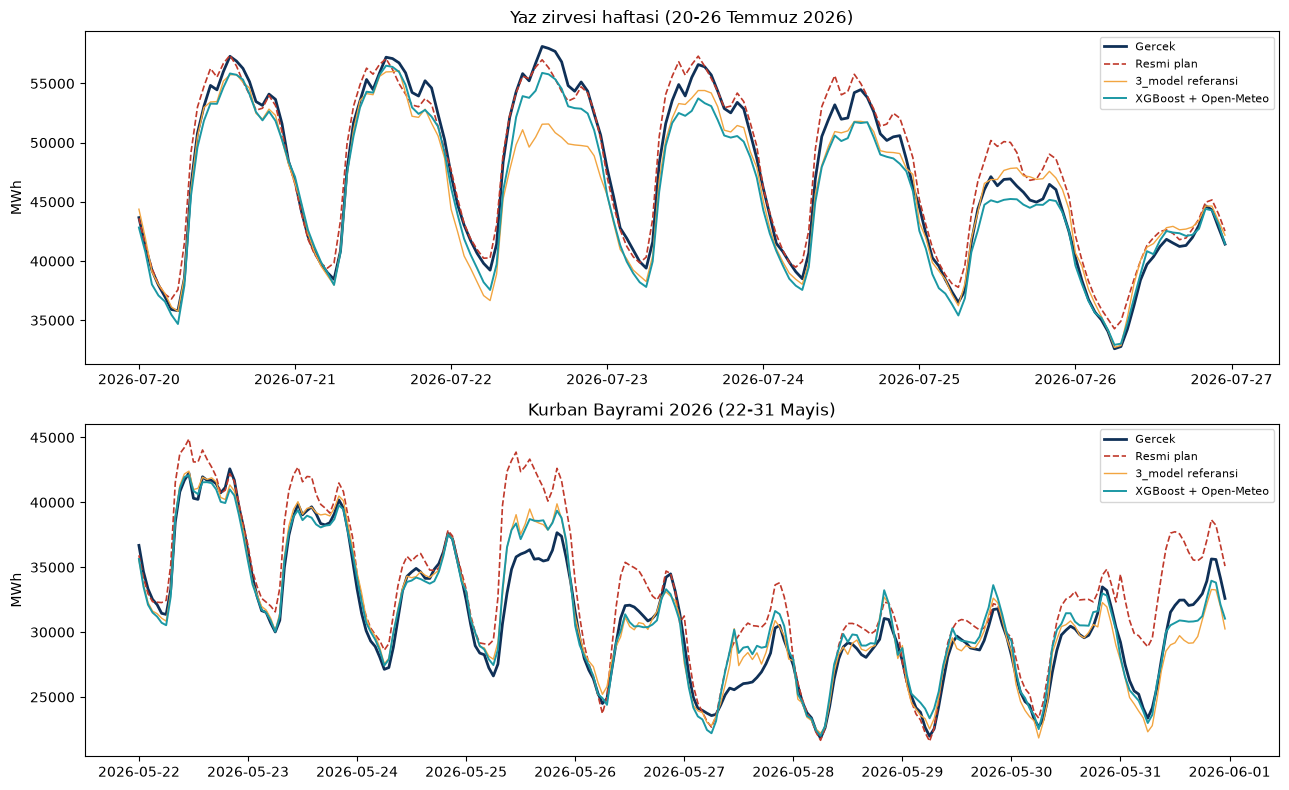

In [18]:
def ciz(ax, bas, bit, baslik):
    p = tt[(tt["date"] >= pd.Timestamp(bas)) & (tt["date"] < pd.Timestamp(bit))]
    ax.plot(p["date"], p["gercek"], color="#0F3057", linewidth=2, label="Gercek")
    ax.plot(p["date"], p["Resmi Yuk Tahmin Plani"], color="#C0392B", linewidth=1.2, linestyle="--", label="Resmi plan")
    ax.plot(p["date"], p["XGBoost gun oncesi (3_model referansi)"], color="#F2A541", linewidth=1, label="3_model referansi")
    if en_iyi != "XGBoost gun oncesi (3_model referansi)":
        ax.plot(p["date"], p[en_iyi], color="#1B98A4", linewidth=1.4, label=en_iyi)
    ax.set_title(baslik); ax.set_ylabel("MWh"); ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
ciz(axes[0], "2026-07-20T00:00:00+03:00", "2026-07-27T00:00:00+03:00", "Yaz zirvesi haftasi (20-26 Temmuz 2026)")
ciz(axes[1], "2026-05-22T00:00:00+03:00", "2026-06-01T00:00:00+03:00", "Kurban Bayrami 2026 (22-31 Mayis)")
plt.tight_layout()
plt.savefig(os.path.join(KOK, "graphs", "tr_gunoncesi_ornek_haftalar.png"), dpi=150)
plt.show()

### F4. Kayıt

- **En iyi model:** `agent/tr_xgb_gunoncesi_en_iyi.json`. Yanında özellik listesi, hedef tipi ve hava kaynağını içeren bir `..._meta.json` dosyası var; Faz 3'te Agent, tahmini bu bilgilerle yeniden üretecek.
- **Sonuçlar:** `metrics/tr_gunoncesi_sonuclari.json` ve `metrics/tr_gunoncesi_test_tahminleri.csv`.

In [19]:
temel, k_eg, k_ot, hedef = MODELLER[en_iyi]
modeller[en_iyi].save_model(os.path.join(KOK, "agent", "tr_xgb_gunoncesi_en_iyi.json"))
meta = {"model": en_iyi, "hedef": hedef, "ozellikler": list(X_olustur(test_k.head(1), temel, k_ot).columns),
        "hava_kaynagi_egitim": k_eg, "hava_kaynagi_calisma": k_ot,
        "om_bazlari_c": {"hdd": BH_OM, "cdd": BC_OM}, "ankara_bazlari_c": {"hdd": BH_TR, "cdd": BC_TR},
        "sehir_agirliklari": AGIRLIK, "secim_olcutu": "dogrulama RMSPE"}
with open(os.path.join(KOK, "agent", "tr_xgb_gunoncesi_en_iyi_meta.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
with open(os.path.join(KOK, "metrics", "tr_gunoncesi_sonuclari.json"), "w", encoding="utf-8") as f:
    json.dump({"en_iyi": en_iyi, "dogrulama": sonuc_dog, "test": sonuc_test,
               "dogrulama_saat": int(len(dog_k)), "test_saat": int(len(test_k))}, f, ensure_ascii=False, indent=2)
tt[["date", "gercek", "gun_tipi"] + list(tahmin_test.keys())].to_csv(
    os.path.join(KOK, "metrics", "tr_gunoncesi_test_tahminleri.csv"), index=False)
print("Kaydedildi. En iyi model:", en_iyi, "| ozellik sayisi:", len(meta["ozellikler"]))

Kaydedildi. En iyi model: XGBoost + Open-Meteo | ozellik sayisi: 18
